### NMF - minimization problem

forked from Ahmad Varasteh github

https://github.com/ahmadvh/Non-Negative-Matrix-factorization---Implemented-in-python

In [1]:
import numpy as np

In [2]:

def random_initialization(X, factor):
    """
    Initialize matrices W and H randomly.

    Parameters:
    - X: Input matrix
    - factor: factor of the factorization

    Returns:
    - W: Initialized W matrix
    - H: Initialized H matrix
    """
    num_genes = X.shape[0]
    num_samples = X.shape[1]
    W = np.random.uniform(1, 2, (num_genes, factor))
    H = np.random.uniform(1, 2, (factor, num_samples))

    return W, H

def nndsvd_initialization(X, factor):
    """
    Initialize matrices W and H using Non-negative Double Singular Value Decomposition (NNDSVD).

    Parameters:
    - X: Input matrix
    - factor: factor of the factorization

    Returns:
    - W: Initialized W matrix
    - H: Initialized H matrix
    """
    u, s, v = np.linalg.svd(X, full_matrices=False)
    v = v.T
    w = np.zeros((X.shape[0], factor))
    h = np.zeros((factor, X.shape[1]))

    w[:, 0] = np.sqrt(s[0]) * np.abs(u[:, 0])
    h[0, :] = np.sqrt(s[0]) * np.abs(v[:, 0].T)

    for i in range(1, factor):
        ui = u[:, i]
        vi = v[:, i]
        ui_pos = (ui >= 0) * ui
        ui_neg = (ui < 0) * -ui
        vi_pos = (vi >= 0) * vi
        vi_neg = (vi < 0) * -vi

        ui_pos_norm = np.linalg.norm(ui_pos, 2)
        ui_neg_norm = np.linalg.norm(ui_neg, 2)
        vi_pos_norm = np.linalg.norm(vi_pos, 2)
        vi_neg_norm = np.linalg.norm(vi_neg, 2)

        norm_pos = ui_pos_norm * vi_pos_norm
        norm_neg = ui_neg_norm * vi_neg_norm

        if norm_pos >= norm_neg:
            w[:, i] = np.sqrt(s[i] * norm_pos) / ui_pos_norm * ui_pos
            h[i, :] = np.sqrt(s[i] * norm_pos) / vi_pos_norm * vi_pos.T
        else:
            w[:, i] = np.sqrt(s[i] * norm_neg) / ui_neg_norm * ui_neg
            h[i, :] = np.sqrt(s[i] * norm_neg) / vi_neg_norm * vi_neg.T

    return w, h

def multiplicative_update(X, k, max_iter, init_mode='random'):
    """
    Perform Multiplicative Update (MU) algorithm for Non-negative Matrix Factorization (NMF).

    Parameters:
    - X: Input matrix
    - k: factor of the factorization
    - max_iter: Maximum number of iterations
    - init_mode: Initialization mode ('random' or 'nndsvd')

    Returns:
    - W: Factorized matrix W
    - H: Factorized matrix H
    - norms: List of Frobenius norms at each iteration
    """
    if init_mode == 'random':
        W, H = random_initialization(X, k)
    else:
        W, H = nndsvd_initialization(X, k)

    norms = []
    epsilon = 1.0e-10
    for _ in range(max_iter):
        # Update H
        W_TA = W.T @ X
        W_TWH = W.T @ W @ H + epsilon
        H *= W_TA / W_TWH

        # Update W
        AH_T = X @ H.T
        WHH_T = W @ H @ H.T + epsilon
        W *= AH_T / WHH_T

        norm = np.linalg.norm(X - W @ H, 'fro')
        norms.append(norm)

    return W, H, norms


Let's try out the methods.

In [3]:
# Generate a random matrix X
X = np.random.rand(400, 20)

# Test random_initialization
factor = 10
W_rand, H_rand = random_initialization(X, factor)
print("Random Initialization:")
print("W:\n", W_rand)
print("H:\n", H_rand)

Random Initialization:
W:
 [[1.06052386 1.092177   1.04691028 ... 1.76712956 1.25060669 1.61366788]
 [1.28392345 1.20819279 1.56521491 ... 1.03027683 1.93385833 1.0956328 ]
 [1.35412431 1.53804882 1.08829655 ... 1.03650249 1.57682517 1.39075604]
 ...
 [1.31144767 1.2840941  1.06990974 ... 1.01546156 1.15977135 1.43158855]
 [1.82307223 1.08352581 1.10714836 ... 1.2816608  1.43799289 1.39232873]
 [1.63627318 1.73287391 1.58639788 ... 1.16246172 1.95538274 1.48680916]]
H:
 [[1.00389825 1.87411293 1.44009713 1.60637972 1.99914916 1.81689957
  1.86958152 1.03231022 1.02020755 1.45162741 1.12292001 1.76397501
  1.45937973 1.04979131 1.98847658 1.44290894 1.38082033 1.8365208
  1.29198349 1.6505344 ]
 [1.99722919 1.05153041 1.57355075 1.15412115 1.66293045 1.68365559
  1.15707332 1.50413096 1.91554377 1.26461362 1.20920257 1.39639231
  1.6952747  1.24801624 1.46262965 1.64867439 1.47641805 1.23211456
  1.4655162  1.73135946]
 [1.22026002 1.15326132 1.03600817 1.07401741 1.9870745  1.31333866


In [4]:
# Test nndsvd_initialization
W_nndsvd, H_nndsvd = nndsvd_initialization(X, factor)
print("NNDSVD Initialization:")
print("W:\n", W_nndsvd)
print("H:\n", H_nndsvd)

NNDSVD Initialization:
W:
 [[ 0.34719731  0.02687175  0.08557192 ...  0.07476626 -0.
   0.07209759]
 [ 0.26389603 -0.          0.01017182 ...  0.01427022  0.07290289
   0.02063749]
 [ 0.31032246 -0.         -0.         ...  0.11756154  0.16304255
   0.12155575]
 ...
 [ 0.29345221  0.084844    0.13390279 ...  0.13224645  0.08258651
  -0.        ]
 [ 0.37739779  0.10589345 -0.         ...  0.15300947 -0.
   0.11330039]
 [ 0.30092993 -0.         -0.         ...  0.14008101  0.11332636
  -0.        ]]
H:
 [[ 1.55870138  1.49621522  1.55597943  1.53752448  1.55420884  1.58170231
   1.46128954  1.42392529  1.47543644  1.54634854  1.48707096  1.42207011
   1.48179338  1.49740232  1.52933776  1.58523052  1.50490915  1.42213519
   1.48546027  1.48391059]
 [-0.          0.14828335 -0.         -0.         -0.         -0.
  -0.         -0.          1.14409256 -0.          0.30036068 -0.
   0.75756059  0.08794035 -0.          0.1177223   0.75188708 -0.
   0.91285396  0.47442527]
 [ 1.13739121  0.32

In [9]:
# Test multiplicative_update
max_iter = 80
W_mu, H_mu, norms = multiplicative_update(X, factor, max_iter)
print("Multiplicative Update:")
print("W:\n", W_mu)
print("H:\n", H_mu)

Multiplicative Update:
W:
 [[1.06627542e+00 2.97493376e+00 7.11627287e-01 ... 3.50545865e+00
  2.68452323e+00 9.77362016e-02]
 [2.91682080e+00 1.88257402e+00 2.01689347e+00 ... 2.72105627e-01
  2.79762001e-02 6.34302639e-01]
 [2.80350233e+00 1.64434459e+00 1.14233814e-01 ... 1.20243298e+00
  6.68681866e-01 2.58066422e+00]
 ...
 [8.62422283e-01 7.03948357e-02 1.59198679e-04 ... 2.63305606e+00
  1.97851526e+00 4.53335127e-01]
 [1.60643713e+00 5.96022458e-01 8.74581296e-01 ... 1.99332706e+00
  9.10827422e-04 3.95184395e+00]
 [3.99817953e-01 2.14761010e-04 1.31370835e+00 ... 9.54763575e-01
  1.57116098e+00 2.51946298e+00]]
H:
 [[2.21203766e-02 1.97398518e-02 3.30371717e-03 3.75214099e-02
  4.99217612e-05 3.60577356e-02 8.93483851e-03 3.67318903e-04
  1.30495477e-03 2.12362229e-03 8.05593780e-03 1.78075287e-01
  9.31402485e-03 1.63306750e-01 4.24655728e-02 3.93462403e-03
  1.16133984e-01 4.72989704e-02 1.12424736e-02 4.59550820e-03]
 [4.81477256e-02 8.02192595e-03 8.06830110e-02 2.98886387e

### Frobenius Norms = ||X - WH||²

In [10]:
print("Frobenius Norms:\n", norms)

Frobenius Norms:
 [np.float64(25.332451283138777), np.float64(25.284054191032837), np.float64(25.231745979527968), np.float64(25.171772664096217), np.float64(25.100746570269532), np.float64(25.01496237952719), np.float64(24.910391512747566), np.float64(24.782784684808703), np.float64(24.62792890779999), np.float64(24.44210184455722), np.float64(24.222731896570703), np.float64(23.96918929869459), np.float64(23.683505798807815), np.float64(23.370709805189346), np.float64(23.038493477152453), np.float64(22.696180670337576), np.float64(22.353319797222138), np.float64(22.018399393557445), np.float64(21.69804216272329), np.float64(21.3967469312748), np.float64(21.117048991182926), np.float64(20.8599131591658), np.float64(20.625195950679743), np.float64(20.412061376660613), np.float64(20.219291202245458), np.float64(20.045481708823623), np.float64(19.88915142285837), np.float64(19.74879448358731), np.float64(19.6229093274856), np.float64(19.510021422662874), np.float64(19.408707891491908), np

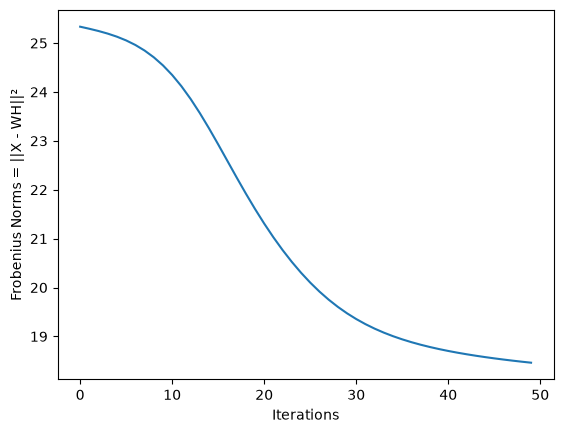

In [7]:
import matplotlib.pyplot as plt
import numpy as np


plt.plot(norms)
plt.ylabel('Frobenius Norms = ||X - WH||²')
plt.xlabel('Iterations')
plt.show()

In [8]:
X.shape, W_nndsvd.shape, H_nndsvd.shape, len(norms)

((400, 20), (400, 10), (10, 20), 50)